In [1]:
import pandas as pd
import numpy as np
import pickle
from statsmodels.tsa.stattools import acf
import matplotlib.pyplot as plt

# Load data and model
df = pd.read_parquet("../data/processed/features.parquet")
with open("../models/lgbm_model.pkl", "rb") as f:
    model = pickle.load(f)

# Prepare test set
test = df[df["split"] == "test"].copy()

features = [
    "forecast_wind_da",
    "lag_1h", "lag_2h", "lag_3h", "lag_6h", "lag_12h", "lag_24h", "lag_48h", "lag_168h",
    "ramp_1h",
    "hour", "day_of_week", "month", "is_weekend",
    "forecast_lag_1h", "forecast_lag_2h", "forecast_lag_24h",
    "is_big_ramp", "is_moderate_ramp",
]

test["predicted_error"] = model.predict(test[features])
test["corrected"] = test["forecast_wind_da"] + test["predicted_error"]
test["corrected_error"] = test["actual_wind_mwh"] - test["corrected"]

residuals = test["corrected_error"].dropna()
print(f"Residuals: {len(residuals)} hours")
print(f"ACF lag-1: {acf(residuals, nlags=1)[1]:.3f}")

Residuals: 743 hours
ACF lag-1: 0.219


In [2]:
# Split January into 4 weeks and compute ACF per week
test_weekly = test.reset_index().set_index("HourUTC")
weeks = {
    "Week 1 (Jan 1-7)": test_weekly["2026-01-01":"2026-01-07"],
    "Week 2 (Jan 8-14)": test_weekly["2026-01-08":"2026-01-14"],
    "Week 3 (Jan 15-21)": test_weekly["2026-01-15":"2026-01-21"],
    "Week 4 (Jan 22-28)": test_weekly["2026-01-22":"2026-01-28"],
}

print("ACF lag-1 by week:")
for name, week_data in weeks.items():
    if len(week_data) > 24:  # need enough points
        week_residuals = week_data["corrected_error"].dropna()
        acf_val = acf(week_residuals, nlags=1)[1]
        print(f"{name}: {acf_val:.3f} (n={len(week_residuals)})")

ACF lag-1 by week:
Week 1 (Jan 1-7): -0.043 (n=168)
Week 2 (Jan 8-14): 0.264 (n=168)
Week 3 (Jan 15-21): 0.106 (n=168)
Week 4 (Jan 22-28): 0.458 (n=168)


In [3]:
# Compare week 1 (best ACF) vs week 4 (worst ACF)
w1 = weeks["Week 1 (Jan 1-7)"]
w4 = weeks["Week 4 (Jan 22-28)"]

print("=== Week 1 (ACF = -0.043) vs Week 4 (ACF = 0.458) ===\n")

# 1. Wind magnitude
print(f"Mean actual wind — W1: {w1['actual_wind_mwh'].mean():.0f}, W4: {w4['actual_wind_mwh'].mean():.0f}")

# 2. Ramp intensity
print(f"Mean |ramp| — W1: {w1['ramp_1h'].abs().mean():.0f}, W4: {w4['ramp_1h'].abs().mean():.0f}")

# 3. Number of big ramp hours
print(f"Big ramp hours — W1: {w1['is_big_ramp'].sum()}, W4: {w4['is_big_ramp'].sum()}")

# 4. Number of moderate ramp hours
print(f"Moderate ramp hours — W1: {w1['is_moderate_ramp'].sum()}, W4: {w4['is_moderate_ramp'].sum()}")

# 5. Model MAE in each week
print(f"Model MAE — W1: {w1['corrected_error'].abs().mean():.1f}, W4: {w4['corrected_error'].abs().mean():.1f}")

# 6. Energinet MAE in each week
print(f"Energinet MAE — W1: {w1['error'].abs().mean():.1f}, W4: {w4['error'].abs().mean():.1f}")

=== Week 1 (ACF = -0.043) vs Week 4 (ACF = 0.458) ===

Mean actual wind — W1: 1819, W4: 3506
Mean |ramp| — W1: 130, W4: 102
Big ramp hours — W1: 2, W4: 0
Moderate ramp hours — W1: 70, W4: 79
Model MAE — W1: 94.8, W4: 102.3
Energinet MAE — W1: 421.5, W4: 890.3


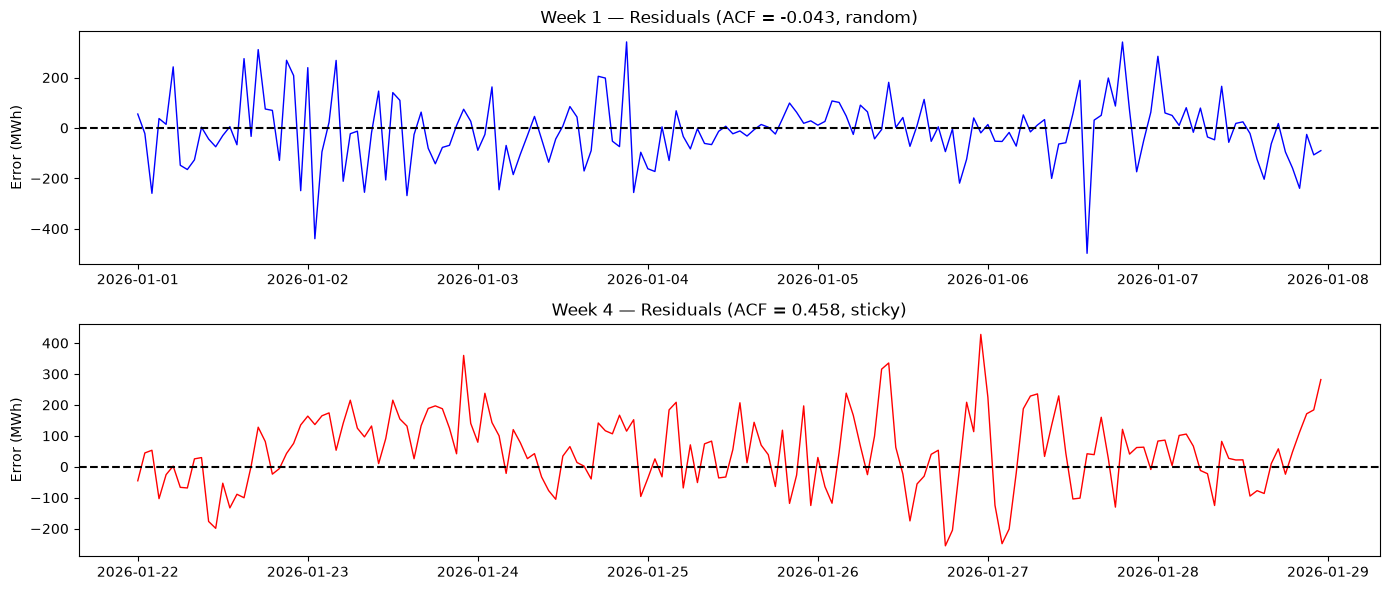

In [4]:
# Plot residuals for week 1 vs week 4
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(w1.index, w1["corrected_error"], color="blue", linewidth=1)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Week 1 — Residuals (ACF = -0.043, random)")
axes[0].set_ylabel("Error (MWh)")

axes[1].plot(w4.index, w4["corrected_error"], color="red", linewidth=1)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Week 4 — Residuals (ACF = 0.458, sticky)")
axes[1].set_ylabel("Error (MWh)")

plt.tight_layout()
plt.show()

In [5]:
# Split residuals by production level
test["high_wind"] = test["actual_wind_mwh"] > 3000

high_wind_residuals = test[test["high_wind"]]["corrected_error"].dropna()
low_wind_residuals = test[~test["high_wind"]]["corrected_error"].dropna()

print(f"ACF lag-1 on high-wind hours (>3000 MWh): {acf(high_wind_residuals, nlags=1)[1]:.3f} (n={len(high_wind_residuals)})")
print(f"ACF lag-1 on normal hours:                 {acf(low_wind_residuals, nlags=1)[1]:.3f} (n={len(low_wind_residuals)})")

print(f"\nMean error on high-wind hours: {high_wind_residuals.mean():.1f} MWh")
print(f"Mean error on normal hours:    {low_wind_residuals.mean():.1f} MWh")

ACF lag-1 on high-wind hours (>3000 MWh): 0.185 (n=329)
ACF lag-1 on normal hours:                 0.160 (n=414)

Mean error on high-wind hours: 54.0 MWh
Mean error on normal hours:    6.3 MWh


In [6]:
# 1. Load validation set
val = df[df["split"] == "validation"].copy()
val["predicted_error"] = model.predict(val[features])
val["corrected"] = val["forecast_wind_da"] + val["predicted_error"]
val["corrected_error"] = val["actual_wind_mwh"] - val["corrected"]

# 2. Find the bias on high-wind hours in validation
val["high_wind"] = val["actual_wind_mwh"] > 3000
val_high_wind_bias = val[val["high_wind"]]["corrected_error"].mean()
print(f"Validation bias on high-wind hours (>3000 MWh): {val_high_wind_bias:.2f} MWh")

# 3. Apply correction to TEST set
test["high_wind"] = test["actual_wind_mwh"] > 3000
test["corrected_bias_fixed"] = test["corrected"]
test.loc[test["high_wind"], "corrected_bias_fixed"] += val_high_wind_bias

# 4. Calculate new MAE on test
mae_before = test["corrected_error"].abs().mean()
test["corrected_error_fixed"] = test["actual_wind_mwh"] - test["corrected_bias_fixed"]
mae_after = test["corrected_error_fixed"].abs().mean()

print(f"\nTest MAE before bias correction: {mae_before:.2f} MWh")
print(f"Test MAE after bias correction:  {mae_after:.2f} MWh")
print(f"Improvement: {mae_before - mae_after:.2f} MWh")

Validation bias on high-wind hours (>3000 MWh): 71.89 MWh

Test MAE before bias correction: 97.29 MWh
Test MAE after bias correction:  92.10 MWh
Improvement: 5.19 MWh
